# Baseline CNN 3 มิติ (3D) · จำแนก Alzheimer's จาก MRI สมอง

## 1. เตรียมข้อมูล

In [1]:
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]          # รหัสคน -> 0 (Normal) หรือ 1 (AD)
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไม่ใช้จนกว่าจะถึงเซลล์สุดท้าย)")

Train      : 163
Validation : 35
Test       : 36 (ไม่ใช้จนกว่าจะถึงเซลล์สุดท้าย)


## 2. ค่าที่ล็อกไว้ (hyperparameter)

In [2]:
MODE = "3D"

# การเทรน
LR = 0.001
WEIGHT_DECAY = 0.0
DROPOUT = 0.0
LABEL_SMOOTHING = 0.0
BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10     # เซฟจุดต่อทุกกี่ epoch (เผื่อหลุดกลางทาง รันซ้ำจะเริ่มต่อให้)

# Augmentation
ROTATE_DEG = 10       # หมุนสุ่มใน ±10 องศา
GAMMA_D = 0.2         # gamma สุ่มใน (1 - 0.2, 1 + 0.2)

# ผลลัพธ์เก็บที่นี่ (โฟลเดอร์ย่อยตามชื่อสูตร) ถ้ามีผลเดิมอยู่แล้วจะถูกนำมาใช้ ไม่เทรนซ้ำ
EXP_DIR = "runs_baseline_3D"
NAME = "bn"
RUN_DIR = os.path.join(EXP_DIR, NAME)
for sub in ("results", "models", "figures"):
    os.makedirs(os.path.join(RUN_DIR, sub), exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 3. Dataset และ augmentation

In [3]:
try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)


MAKE_KW = {}      # 3D ใช้ volume เต็ม ไม่ต้องกำหนดขนาดสไลซ์


def adjust_gamma(x, seed, epoch, sid, d):
    # ยกกำลังภาพด้วย gamma ที่สุ่มใน (1-d, 1+d) หนึ่งค่าต่อคนต่อ epoch (0 ยังเป็น 0, 1 ยังเป็น 1)
    g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - d, 1 + d)
    return (np.clip(x, 0, 1) ** g).astype(np.float32)


class MRIDataset(Dataset):
    # train=True: หมุน + gamma / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train
        self.seed = 1334      # ตั้งใหม่ก่อนเทรนแต่ละ seed
        self.epoch = 1        # ตั้งใหม่ทุก epoch

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])
        angle = 0.0
        if self.train:
            angle = AL.angle_for(self.seed, self.epoch, sid, ROTATE_DEG)
        x = PL.make_input(self.volumes[i], MODE, angle, **MAKE_KW)
        x = np.ascontiguousarray(x, dtype=np.float32)
        if self.train:
            x = adjust_gamma(x, self.seed, self.epoch, sid, GAMMA_D)
        return torch.from_numpy(x), self.y[i]


train_data = MRIDataset(train_ids, train=True)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

อินพุตต่อคน: (1, 128, 128, 96)


### ตัวอย่างภาพ: ต้นฉบับเทียบกับหลัง augmentation (คนแรกใน train, แสดงสไลซ์ axial)

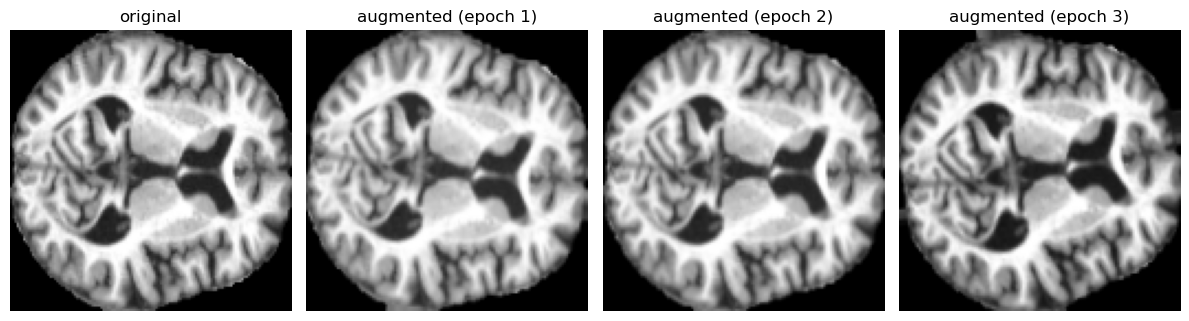

In [4]:
def axial_slice(x):
    return x[0, :, :, x.shape[3] // 2]       # ตัดกลางแกนสุดท้าย (axial)


preview = MRIDataset(train_ids[:1], train=True)
preview.seed = SEEDS[0]
preview.train = False
img_orig = axial_slice(preview[0][0].numpy())
preview.train = True
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
axes[0].imshow(img_orig, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("original")
for k, ep in enumerate((1, 2, 3)):
    preview.epoch = ep
    axes[k + 1].imshow(axial_slice(preview[0][0].numpy()), cmap="gray", vmin=0, vmax=1)
    axes[k + 1].set_title(f"augmented (epoch {ep})")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

## 4. โมเดล CNN 3 ชั้น (มี BatchNorm)

In [5]:
class SimpleCNN(nn.Module):
    # Conv 3 ชั้น (kernel 3x3x3 + BatchNorm) -> Global Average Pooling -> Linear 2 คลาส (Normal / AD)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=3, padding=1, bias=False),     # ชั้น 1: 1 -> 8 channel  (128x128x96 -> 64x64x48 หลัง MaxPool)
            nn.BatchNorm3d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(8, 16, kernel_size=3, padding=1, bias=False),    # ชั้น 2: 8 -> 16 channel  (64x64x48 -> 32x32x24)
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(16, 32, kernel_size=3, padding=1, bias=False),   # ชั้น 3: 16 -> 32 channel (32x32x24 -> 16x16x12)
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
        )
        self.gap = nn.AdaptiveAvgPool3d(1)                  # เฉลี่ยทั้งก้อน 16x16x12 เหลือ 1 ค่าต่อ channel -> 32 ค่า
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32, 2)                          # 32 ฟีเจอร์ -> 2 คลาส

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(self.gap(x))
        return self.fc(x)


# ดูรูปร่างข้อมูลในแต่ละชั้น และจำนวน parameter
_m = SimpleCNN().eval()
_x = torch.zeros(1, *IN_SHAPE)
print("input   ", tuple(_x.shape[1:]))
with torch.no_grad():
    k = 0
    for layer in _m.features:
        _x = layer(_x)
        if isinstance(layer, nn.MaxPool3d):
            k += 1
            print(f"layer {k}  ", tuple(_x.shape[1:]))
print("จำนวน parameter:", f"{sum(q.numel() for q in _m.parameters()):,}")
del _m, _x

input    (1, 128, 128, 96)
layer 1   (8, 64, 64, 48)
layer 2   (16, 32, 32, 24)
layer 3   (32, 16, 16, 12)
จำนวน parameter: 17,674


In [6]:
import time, math, torch, torch.nn as nn

def profile(model, x_shape, batch=8, n_train=163, lr=1e-3, steps=20, epochs=200, device="cuda"):
    x = torch.randn(batch, *x_shape, device=device)
    y = torch.randint(0, 2, (batch,), device=device)
    model = model.to(device).train()

    n_all = sum(p.numel() for p in model.parameters())
    n_train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    crit = nn.CrossEntropyLoss()
    def step():
        opt.zero_grad(); crit(model(x), y).backward(); opt.step()

    for _ in range(3): step()
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(steps): step()
    torch.cuda.synchronize()
    sec_per_step = (time.time() - t0) / steps

    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    est_min = sec_per_step * math.ceil(n_train / batch) * epochs / 60
    print(f"พารามิเตอร์ทั้งหมด {n_all:,} | ที่ฝึกได้ {n_train_p:,} | "
          f"หน่วยความจำสูงสุด {peak_gb:.2f} GB | เวลาฝึกโดยประมาณ {est_min:.1f} นาที")
profile(SimpleCNN(), IN_SHAPE)

พารามิเตอร์ทั้งหมด 17,674 | ที่ฝึกได้ 17,674 | หน่วยความจำสูงสุด 1.56 GB | เวลาฝึกโดยประมาณ 4.2 นาที


## 5. เทรน

In [6]:
def evaluate(model, loader, criterion):
    # วัดผลบน loader (ไม่แตะน้ำหนัก)
    model.eval()
    running_loss = 0
    probs, preds, trues = [], [], []
    with torch.no_grad():
        for images, y in loader:
            images, y = images.to(device), y.to(device)
            outputs = model(images)
            running_loss += criterion(outputs, y).item()
            probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
            preds.extend(outputs.argmax(1).cpu().numpy())
            trues.extend(y.cpu().numpy())
    tn, fp, fn, tp = confusion_matrix(trues, preds, labels=[0, 1]).ravel()
    return {
        "loss": running_loss / len(loader),
        "AUC": float(roc_auc_score(trues, probs)),
        "Accuracy": float(accuracy_score(trues, preds)),
        "F1": float(f1_score(trues, preds, zero_division=0)),
        "Sensitivity": float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,    # AD ที่ทายถูก / AD ทั้งหมด
        "Specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,    # Normal ที่ทายถูก / Normal ทั้งหมด
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


# ค่าตั้งทั้งหมดของการเทรน (ใช้เช็กว่าผลเดิมที่มีอยู่ตั้งค่าเหมือนกันหรือไม่)
CONFIG = {"mode": MODE, "pretrained": False, "model": {"width": 8, "kernel": 3, "batchnorm": True},
          "lr": LR, "dropout": DROPOUT, "weight_decay": WEIGHT_DECAY, "label_smoothing": LABEL_SMOOTHING,
          "rotate_deg": ROTATE_DEG, "gamma_d": GAMMA_D, "noise_std": 0.0, "noise_type": "gaussian",
          "batch_size": BATCH_SIZE, "epochs": EPOCHS}


def train_one_seed(SEED):
    json_path = os.path.join(RUN_DIR, "results", f"seed{SEED}.json")
    best_pt = os.path.join(RUN_DIR, "models", f"seed{SEED}_best.pt")
    last_pt = os.path.join(RUN_DIR, "models", f"seed{SEED}_last.pt")      # จุดเซฟระหว่างเทรน (ลบเมื่อจบ)

    if os.path.exists(json_path) and os.path.exists(best_pt):
        if json.load(open(json_path))["config"] == CONFIG:
            print(f"seed {SEED}: มีผลแล้ว ข้ามไป")
            return

    print("=" * 60)
    print(f"เทรน seed {SEED}")
    print("=" * 60)

    set_seed(SEED)
    model = SimpleCNN().to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    val_criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    train_data.seed = SEED
    names = ["train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1", "val_auc", "val_sens", "val_spec"]
    hist = {k: [] for k in names}
    best_combo, best_epoch, best_val, best_state = -1, -1, None, None
    start_epoch, minutes_before = 0, 0.0

    # ถ้ามีจุดเซฟค้าง (เคยหลุดกลางทาง) ให้เริ่มต่อจากจุดนั้น
    if os.path.exists(last_pt):
        ck = torch.load(last_pt, map_location=device, weights_only=False)
        if ck["config"] == CONFIG:
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])
            hist, best_combo, best_epoch = ck["hist"], ck["best_combo"], ck["best_epoch"]
            best_val, best_state = ck["best_val"], ck["best_state"]
            start_epoch, minutes_before = ck["epoch"], ck["minutes"]
            print(f"เริ่มต่อจาก epoch {start_epoch + 1}")

    t_start = time.time()
    g = torch.Generator()

    for epoch in range(start_epoch, EPOCHS):
        # ---------- train ----------
        train_data.epoch = epoch + 1
        g.manual_seed(SEED * 1000 + epoch)           # ลำดับสลับภาพของแต่ละ epoch ผูกกับ (seed, epoch)
        train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=NUM_WORKERS)

        model.train()
        running_loss = 0
        train_preds, train_trues = [], []
        for images, y in tqdm(train_loader, desc=f"seed {SEED} epoch {epoch+1}/{EPOCHS}", leave=False):
            images, y = images.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            train_preds.extend(outputs.argmax(1).cpu().numpy())
            train_trues.extend(y.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_acc = accuracy_score(train_trues, train_preds)
        train_f1 = f1_score(train_trues, train_preds, zero_division=0)

        # ---------- validation (ไม่ทำ augmentation) ----------
        v = evaluate(model, val_loader, val_criterion)
        for k, val in zip(names, (train_loss, train_acc, train_f1, v["loss"], v["Accuracy"], v["F1"], v["AUC"], v["Sensitivity"], v["Specificity"])):
            hist[k].append(float(val))

        # ---------- เลือก epoch ที่ดีที่สุดจาก val: (AUC + F1) / 2 สูงสุด ----------
        combo = (v["AUC"] + v["F1"]) / 2
        if combo > best_combo:
            best_combo, best_epoch = combo, epoch + 1
            best_val = {k: v[k] for k in ("AUC", "Accuracy", "F1", "Sensitivity", "Specificity", "TN", "FP", "FN", "TP")}
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss {train_loss:.4f} | Val Loss {v['loss']:.4f} | "
                  f"AUC {v['AUC']:.4f} | F1 {v['F1']:.4f} | Sens {v['Sensitivity']:.3f} | Spec {v['Specificity']:.3f}")

        minutes = minutes_before + (time.time() - t_start) / 60
        if (epoch + 1) % CHECKPOINT_EVERY == 0 and (epoch + 1) < EPOCHS:
            torch.save({"config": CONFIG, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "hist": hist, "best_combo": best_combo, "best_epoch": best_epoch, "best_val": best_val,
                        "best_state": best_state, "epoch": epoch + 1, "minutes": minutes}, last_pt)

    # ---------- จบ: เก็บน้ำหนัก (.pt) และผล (.json) ----------
    torch.save(best_state, best_pt)
    result = {
        "name": NAME, "seed": SEED, "config": CONFIG,
        "best_epoch": best_epoch, "best_combo": float(best_combo),
        "val_best": best_val,
        "val_last": {"AUC": hist["val_auc"][-1], "Accuracy": hist["val_acc"][-1], "F1": hist["val_f1"][-1],
                     "Sensitivity": hist["val_sens"][-1], "Specificity": hist["val_spec"][-1]},
        "minutes": round(minutes, 1),
        "history": hist,
    }
    json.dump(result, open(json_path, "w"), indent=1)
    if os.path.exists(last_pt):
        os.remove(last_pt)
    print(f"seed {SEED} เสร็จแล้ว | best epoch {best_epoch} | ใช้เวลา {result['minutes']} นาที\n")


for SEED in SEEDS:
    train_one_seed(SEED)

seed 1334: มีผลแล้ว ข้ามไป
seed 42: มีผลแล้ว ข้ามไป
seed 2026: มีผลแล้ว ข้ามไป
seed 7: มีผลแล้ว ข้ามไป
seed 2002: มีผลแล้ว ข้ามไป


## 6. ผลบน Validation

In [7]:
runs = []
for s in SEEDS:
    p = os.path.join(RUN_DIR, "results", f"seed{s}.json")
    if os.path.exists(p):
        runs.append(json.load(open(p)))
METRICS = ["AUC", "F1", "Accuracy", "Sensitivity", "Specificity"]

# ผลของแต่ละ seed
rows = []
for r in runs:
    h = r["history"]
    row = {"seed": r["seed"], "best_epoch": r["best_epoch"]}
    for m in METRICS:
        row[f"{m} (best)"] = r["val_best"][m]
    row["AUC (last)"] = r["val_last"]["AUC"]
    row["train loss (last)"] = h["train_loss"][-1]
    row["val loss (last)"] = h["val_loss"][-1]
    rows.append(row)
per_seed = pd.DataFrame(rows)
display(per_seed.round(3))
per_seed.to_csv(os.path.join(EXP_DIR, "summary_per_seed.csv"), index=False)


def mean_sd(key):
    # key = "val_best" (epoch ที่เลือกจาก val) หรือ "val_last" (epoch สุดท้าย)
    row = {"จำนวน seed": len(runs)}
    for m in METRICS:
        vals = [r[key][m] for r in runs]
        sd = np.std(vals, ddof=1) if len(vals) > 1 else float("nan")
        row[m] = f"{np.mean(vals):.3f} ± {sd:.3f}"
    return pd.DataFrame([row])


print("\nepoch ที่เลือกจาก validation  (mean ± SD ข้าม seed)")
display(mean_sd("val_best"))
print("epoch สุดท้าย  (mean ± SD ข้าม seed)")
display(mean_sd("val_last"))

,seed,best_epoch,AUC (best),F1 (best),Accuracy (best),Sensitivity (best),Specificity (best),AUC (last),train loss (last),val loss (last)
0,1334,115,0.757,0.706,0.714,0.800,0.65,0.780,0.425,0.563
1,42,179,0.773,0.743,0.743,0.867,0.65,0.757,0.468,0.995
2,2026,169,0.743,0.743,0.743,0.867,0.65,0.740,0.428,1.222
3,7,133,0.753,0.706,0.714,0.800,0.65,0.730,0.470,4.850
4,2002,85,0.723,0.706,0.714,0.800,0.65,0.697,0.492,1.721



epoch ที่เลือกจาก validation  (mean ± SD ข้าม seed)


,จำนวน seed,AUC,F1,Accuracy,Sensitivity,Specificity
0,5,0.750 ± 0.018,0.721 ± 0.020,0.726 ± 0.016,0.827 ± 0.037,0.650 ± 0.000


epoch สุดท้าย  (mean ± SD ข้าม seed)


,จำนวน seed,AUC,F1,Accuracy,Sensitivity,Specificity
0,5,0.741 ± 0.031,0.491 ± 0.276,0.537 ± 0.074,0.707 ± 0.428,0.410 ± 0.407


### กราฟการเรียนรู้

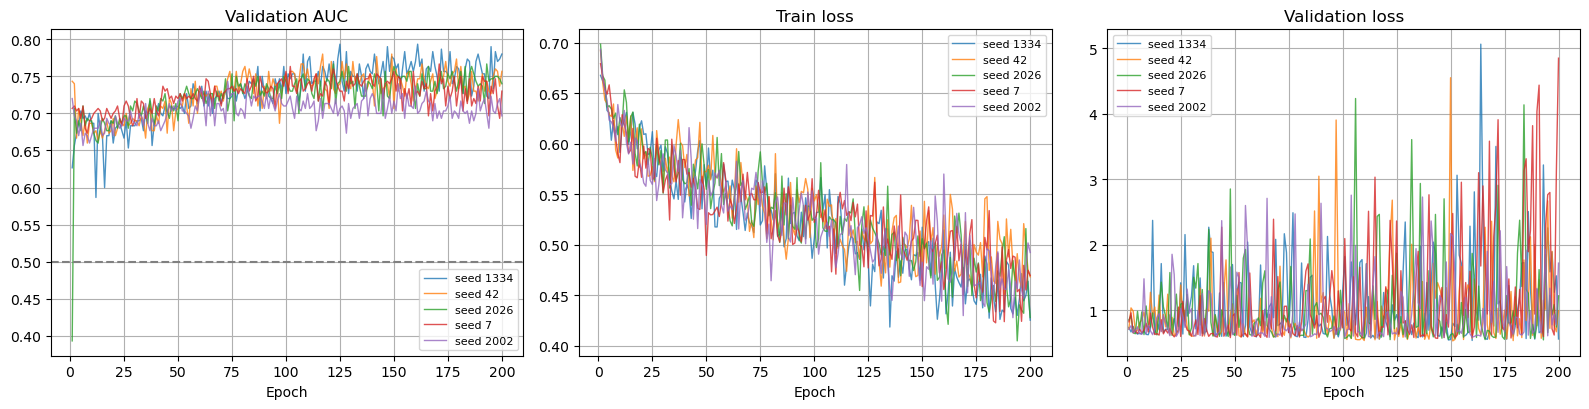

In [8]:
colors = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for n, r in enumerate(runs):
    h = r["history"]
    ep = range(1, len(h["val_auc"]) + 1)
    axes[0].plot(ep, h["val_auc"], color=colors[n % 10], alpha=0.8, linewidth=1, label=f"seed {r['seed']}")
    axes[1].plot(ep, h["train_loss"], color=colors[n % 10], alpha=0.8, linewidth=1, label=f"seed {r['seed']}")
    axes[2].plot(ep, h["val_loss"], color=colors[n % 10], alpha=0.8, linewidth=1, label=f"seed {r['seed']}")

axes[0].axhline(0.5, color="gray", linestyle="--")
axes[0].set_title("Validation AUC")
axes[1].set_title("Train loss")
axes[2].set_title("Validation loss")
for a in axes:
    a.set_xlabel("Epoch")
    a.grid(True)
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "learning_curves.png"), dpi=150)
plt.show()

In [9]:
# กราฟ 2x2 ของแต่ละ seed (เส้นประ = epoch ที่เลือก) เก็บเป็นไฟล์รูปในโฟลเดอร์ figures
for r in runs:
    h = r["history"]
    best_epoch = r["best_epoch"]
    ep = range(1, len(h["train_loss"]) + 1)

    plt.figure(figsize=(12, 8))
    plt.subplot(2, 2, 1)
    plt.plot(ep, h["train_loss"], label="train loss")
    plt.plot(ep, h["val_loss"], label="val loss")
    plt.title("Loss")
    plt.subplot(2, 2, 2)
    plt.plot(ep, h["train_acc"], label="train acc")
    plt.plot(ep, h["val_acc"], label="val acc")
    plt.title("Accuracy")
    plt.subplot(2, 2, 3)
    plt.plot(ep, h["train_f1"], label="train f1")
    plt.plot(ep, h["val_f1"], label="val f1")
    plt.title("F1")
    plt.subplot(2, 2, 4)
    plt.plot(ep, h["val_auc"], label="val auc")
    plt.plot(ep, h["val_sens"], label="val sensitivity", alpha=0.6)
    plt.plot(ep, h["val_spec"], label="val specificity", alpha=0.6)
    plt.title("Val AUC / Sensitivity / Specificity")
    for i in range(1, 5):
        plt.subplot(2, 2, i)
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.grid(True)
        plt.legend()
    plt.suptitle(f"seed {r['seed']} (best epoch = {best_epoch})")
    plt.tight_layout()
    plt.savefig(os.path.join(RUN_DIR, "figures", f"curves_seed{r['seed']}.png"), dpi=150)
    plt.close()
print("บันทึกกราฟแล้วที่", os.path.join(RUN_DIR, "figures"))

บันทึกกราฟแล้วที่ runs_baseline_3D/bn/figures


## ข้อควรระวังในการอ่านผล

## 7. Test (เปิดครั้งเดียว หลังล็อกโครงสร้างและค่าทั้งหมดแล้ว)

,seed,AUC,F1,Accuracy,Sensitivity,Specificity,TN,FP,FN,TP
0,1334,0.759,0.667,0.667,0.800,0.571,12,9,3,12
1,42,0.781,0.625,0.667,0.667,0.667,14,7,5,10
2,2026,0.794,0.684,0.667,0.867,0.524,11,10,2,13
3,7,0.746,0.667,0.667,0.800,0.571,12,9,3,12
4,2002,0.749,0.645,0.694,0.667,0.714,15,6,5,10



Baseline CNN 3D Evaluation (Test, mean ± SD ข้าม 5 seed)
AUC         : 0.7657 ± 0.0207
F1          : 0.6575 ± 0.0229
Accuracy    : 0.6722 ± 0.0124
Sensitivity : 0.7600 ± 0.0894
Specificity : 0.6095 ± 0.0782
Confusion Matrix (เฉลี่ยข้าม seed): TN=12.8, FP=8.2, FN=3.6, TP=11.4


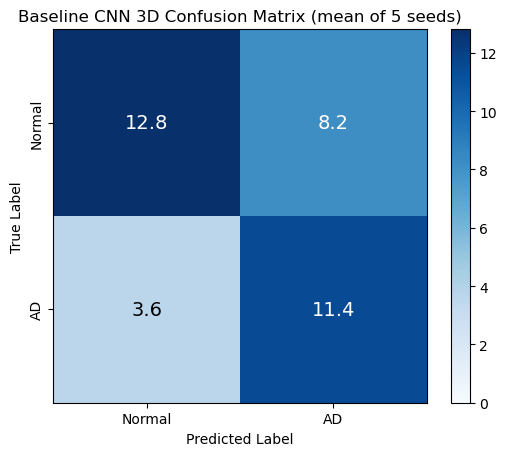

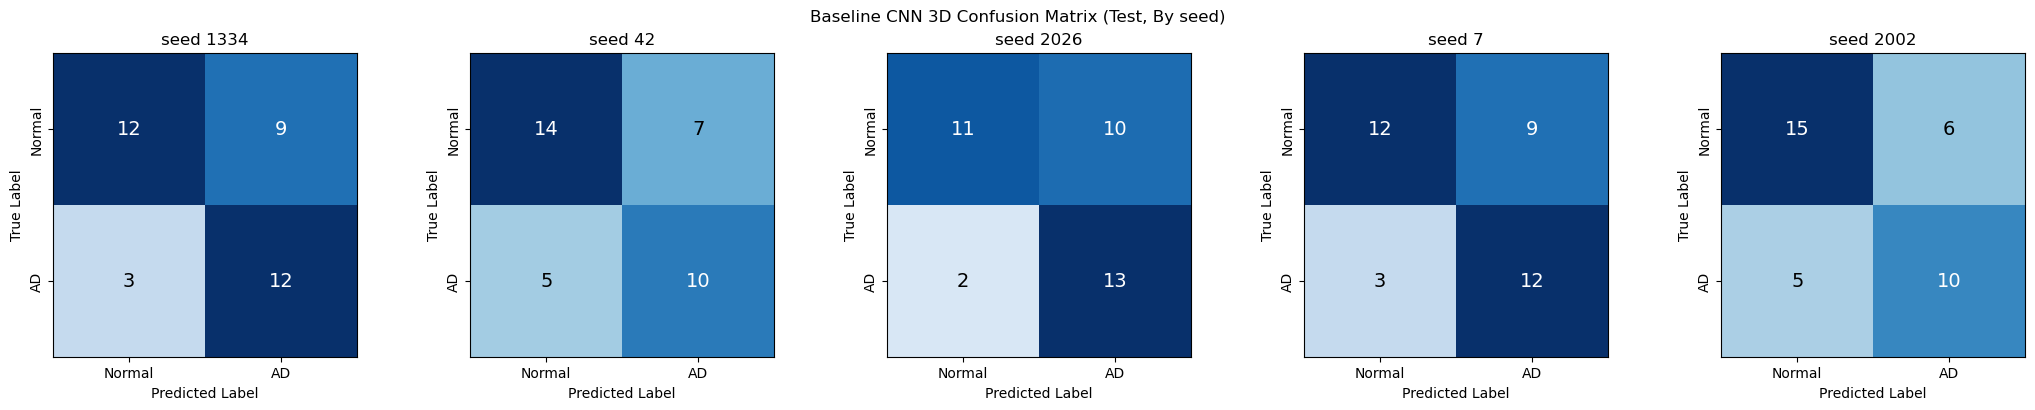

In [10]:
RUN_TEST = True
MODEL_NAME = "Baseline CNN 3D"
TEST_CSV = os.path.join(EXP_DIR, "test_results.csv")

def show_test_report(tt, name, out_dir, tag):
    # ตารางผลรายค่าเริ่มต้นสุ่ม + สรุป mean ± SD + ภาพ Confusion Matrix
    display(tt.round(3))
    print(f"\n{name} Evaluation (Test, mean ± SD ข้าม {len(tt)} seed)")
    for m in METRICS:
        print(f"{m:12s}: {tt[m].mean():.4f} ± {tt[m].std(ddof=1):.4f}")
    cms = [np.array([[r.TN, r.FP], [r.FN, r.TP]]) for r in tt.itertuples()]
    mean_cm = np.mean(cms, axis=0)
    print(f"Confusion Matrix (เฉลี่ยข้าม seed): TN={mean_cm[0,0]:.1f}, FP={mean_cm[0,1]:.1f}, FN={mean_cm[1,0]:.1f}, TP={mean_cm[1,1]:.1f}")

    def draw(ax, cm, title, fmt, colorbar=False):
        im = ax.imshow(cm, cmap="Blues", vmin=0)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "AD"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "AD"], rotation=90, va="center")
        ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
        ax.set_title(title)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
        if colorbar:
            plt.colorbar(im, ax=ax)

    # ภาพเดียว: เฉลี่ยข้าม seed
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    draw(ax, mean_cm, f"{name} Confusion Matrix (mean of {len(tt)} seeds)", ".1f", colorbar=True)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"confusion_matrix_{tag}_mean.png"), dpi=200)
    plt.show()

    # แยกรายค่าเริ่มต้นสุ่ม
    fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 4))
    for ax, cm, r in zip(np.atleast_1d(axes), cms, tt.itertuples()):
        draw(ax, cm, f"seed {r.seed}", "d")
    fig.suptitle(f"{name} Confusion Matrix (Test, By seed)")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"confusion_matrix_{tag}_per_seed.png"), dpi=200)
    plt.show()

if RUN_TEST:
    if os.path.exists(TEST_CSV):
        # เปิด test ไปแล้ว: อ่านผลจากไฟล์ที่บันทึกไว้ ไม่ประเมินซ้ำ
        print(f"เปิด test ไปแล้ว แสดงผลจากไฟล์ {TEST_CSV} (ไม่ประเมินซ้ำ)")
        test_table = pd.read_csv(TEST_CSV)
    else:
        test_data = MRIDataset(test_ids, train=False)
        test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
        criterion = nn.CrossEntropyLoss()
        test_rows = []
        for SEED in SEEDS:
            pt = os.path.join(RUN_DIR, "models", f"seed{SEED}_best.pt")
            model = SimpleCNN().to(device)
            model.load_state_dict(torch.load(pt, map_location=device))      # น้ำหนักของ epoch ที่เลือกจาก val
            t = evaluate(model, test_loader, criterion)
            test_rows.append({"seed": SEED, **{m: t[m] for m in METRICS}, "TN": t["TN"], "FP": t["FP"], "FN": t["FN"], "TP": t["TP"]})
        test_table = pd.DataFrame(test_rows)
        test_table.to_csv(TEST_CSV, index=False)
    show_test_report(test_table, MODEL_NAME, EXP_DIR, "Baseline_CNN_3D")
else:
    print("ยังไม่เปิด test")
